# 🦐 Prawn — AquaCare AI DO Training

This notebook is **only for 🦐 Prawn Dissolved Oxygen (DO) prediction**.

It will:
- load the 🦐 Prawn DO dataset
- inspect and clean the data
- select useful water-quality/environment features
- train a Random Forest regression model
- evaluate MAE, RMSE and R²
- plot Actual vs Predicted DO
- plot feature importance
- save the trained model as `models/prawn_do_model.pkl`

**No fake data and no fake predictions are created.**


In [ ]:
%pip install pandas numpy scikit-learn matplotlib joblib


## 1. Project path and dataset search

Project folder:

`C:\Users\NANDINI\Desktop\AQUA CARE`


In [3]:
from pathlib import Path
import pandas as pd

# =========================================================
# PRAWN DO DATASET
# =========================================================

DATASET_PATH = Path(
    r"C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\prawn_DO.csv"
)

# CSV file unna folder ni project folder ga teesukuntam
PROJECT_DIR = DATASET_PATH.parent

# Models folder
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# =========================================================
# CHECK DATASET
# =========================================================

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"❌ Prawn DO dataset not found:\n{DATASET_PATH}"
    )

print("✅ Prawn DO dataset found")
print("Dataset:", DATASET_PATH)

print("\n✅ Project folder:")
print(PROJECT_DIR)

print("\n✅ Models folder:")
print(MODELS_DIR)

# =========================================================
# LOAD DATASET
# =========================================================

df = pd.read_csv(DATASET_PATH)

print("\nDataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

✅ Prawn DO dataset found
Dataset: C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\prawn_DO.csv

✅ Project folder:
C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn

✅ Models folder:
C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\models

Dataset Shape: (5760, 15)

Columns:
['timestamp', 'pond_id', 'species', 'water_temp_C', 'pH', 'salinity_ppt', 'DO_mg_L', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'aerator_on', 'feed_kg', 'rainfall_mm', 'DO_status', 'mortality_risk']


,timestamp,pond_id,species,water_temp_C,pH,salinity_ppt,DO_mg_L,ammonia_mg_L,nitrite_mg_L,turbidity_NTU,aerator_on,feed_kg,rainfall_mm,DO_status,mortality_risk
0,2026-08-01 00:00:00,PR1,Vannamei (L. vannamei),27.00,7.59,14.53,2.89,0.131,0.068,27.7,1,0.0,0.0,Critical,High
1,2026-08-01 01:00:00,PR1,Vannamei (L. vannamei),25.96,7.42,15.05,4.68,0.097,0.055,28.5,1,0.0,0.0,Low,Low
2,2026-08-01 02:00:00,PR1,Vannamei (L. vannamei),25.68,7.34,15.24,4.43,0.104,0.066,38.9,1,0.0,0.0,Low,Medium
3,2026-08-01 03:00:00,PR1,Vannamei (L. vannamei),26.04,7.37,15.17,3.99,0.095,0.069,35.2,1,0.0,0.0,Low,Medium
4,2026-08-01 04:00:00,PR1,Vannamei (L. vannamei),26.56,7.50,14.80,3.84,0.122,0.074,37.3,1,0.0,0.0,Low,Medium


## 2. Load and inspect the dataset

In [4]:
df = pd.read_csv(r"C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\prawn_DO.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(list(df.columns))

display(df.head())


Shape: (5760, 15)

Columns:
['timestamp', 'pond_id', 'species', 'water_temp_C', 'pH', 'salinity_ppt', 'DO_mg_L', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'aerator_on', 'feed_kg', 'rainfall_mm', 'DO_status', 'mortality_risk']


,timestamp,pond_id,species,water_temp_C,pH,salinity_ppt,DO_mg_L,ammonia_mg_L,nitrite_mg_L,turbidity_NTU,aerator_on,feed_kg,rainfall_mm,DO_status,mortality_risk
0,2026-08-01 00:00:00,PR1,Vannamei (L. vannamei),27.00,7.59,14.53,2.89,0.131,0.068,27.7,1,0.0,0.0,Critical,High
1,2026-08-01 01:00:00,PR1,Vannamei (L. vannamei),25.96,7.42,15.05,4.68,0.097,0.055,28.5,1,0.0,0.0,Low,Low
2,2026-08-01 02:00:00,PR1,Vannamei (L. vannamei),25.68,7.34,15.24,4.43,0.104,0.066,38.9,1,0.0,0.0,Low,Medium
3,2026-08-01 03:00:00,PR1,Vannamei (L. vannamei),26.04,7.37,15.17,3.99,0.095,0.069,35.2,1,0.0,0.0,Low,Medium
4,2026-08-01 04:00:00,PR1,Vannamei (L. vannamei),26.56,7.50,14.80,3.84,0.122,0.074,37.3,1,0.0,0.0,Low,Medium


## 3. Detect DO target and select useful features

Supported target names:
- `DO_mg_L`
- `dissolved_oxygen_mg_l`
- `dissolved_oxygen`
- `DO`

Useful available inputs may include temperature, pH, salinity, ammonia, nitrite, turbidity, aerator, feed and rainfall.


In [5]:
def normalize_name(value):
    s = str(value).strip().lower()
    for ch in [" ", "-", "/", "\\", "(", ")", "[", "]", "{", "}", "."]:
        s = s.replace(ch, "_")
    while "__" in s:
        s = s.replace("__", "_")
    return s.strip("_")

name_map = {normalize_name(c): c for c in df.columns}

target_candidates = [
    "do_mg_l",
    "dissolved_oxygen_mg_l",
    "dissolved_oxygen",
    "do"
]

target_col = None

for candidate in target_candidates:
    if candidate in name_map:
        target_col = name_map[candidate]
        break

if target_col is None:
    for normalized, original in name_map.items():
        if "oxygen" in normalized and ("mg" in normalized or normalized == "dissolved_oxygen"):
            target_col = original
            break

if target_col is None:
    raise ValueError(
        "DO target column was not found. Expected DO_mg_L or dissolved_oxygen_mg_l."
    )

aliases = {
    "water_temp": ["water_temp_c", "water_temperature_c", "temperature_c", "temperature"],
    "ph": ["ph"],
    "salinity": ["salinity_ppt", "salinity"],
    "ammonia": ["ammonia_mg_l", "ammonia"],
    "nitrite": ["nitrite_mg_l", "nitrite"],
    "turbidity": ["turbidity_ntu", "turbidity"],
    "feed": ["feed_kg", "feeding_rate_kg", "feed_amount_kg", "feeding_rate"],
    "rainfall": ["rainfall_mm", "rainfall"],
    "aerator": ["aerator_on", "aerator_status", "aerator"],
    "stocking_density": ["stocking_density"],
    "pond_area": ["pond_area_acres", "pond_area"],
    "average_weight": ["prawn_average_weight_g", "average_weight_g"],
    "length": ["prawn_length_cm", "length_cm"],
}

feature_cols = []

for alias_list in aliases.values():
    for alias in alias_list:
        if alias in name_map and name_map[alias] != target_col:
            feature_cols.append(name_map[alias])
            break

for normalized, original in name_map.items():
    if normalized in {"species", "fish_species", "prawn_species", "species_name"}:
        if original != target_col:
            feature_cols.append(original)

feature_cols = list(dict.fromkeys(feature_cols))

if not feature_cols:
    raise ValueError("No suitable input features were found in this dataset.")

print("Target:", target_col)
print("Features:", feature_cols)


Target: DO_mg_L
Features: ['water_temp_C', 'pH', 'salinity_ppt', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'feed_kg', 'rainfall_mm', 'aerator_on', 'species']


## 4. Clean data

In [6]:
work = df[feature_cols + [target_col]].copy()

work[target_col] = pd.to_numeric(work[target_col], errors="coerce")
work = work.dropna(subset=[target_col])

print("Rows after cleaning:", len(work))
display(work.isna().sum().to_frame("missing"))


Rows after cleaning: 5760


,missing
water_temp_C,0
pH,0
salinity_ppt,0
ammonia_mg_L,0
nitrite_mg_L,0
turbidity_NTU,0
feed_kg,0
rainfall_mm,0
aerator_on,0
species,0


## 5. Train the Random Forest DO model

In [16]:
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =========================================================
# 🦐 PRAWN DO - EXTRA TREES
# =========================================================

# Your already prepared data
X = work[feature_cols].copy()
y = work[target_col].copy()

# Remove missing target rows
valid = y.notna()

X = X.loc[valid].copy()
y = y.loc[valid].copy()

# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

# =========================================================
# Separate numeric and categorical columns
# =========================================================

numeric_cols = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("\nNumeric columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

# =========================================================
# Preprocessing
# =========================================================

transformers = []

if numeric_cols:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    transformers.append(
        ("num", numeric_pipeline, numeric_cols)
    )

if categorical_cols:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    transformers.append(
        ("cat", categorical_pipeline, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# =========================================================
# Extra Trees Model
# =========================================================

prawn_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    max_features=1.0
)

# =========================================================
# Complete Pipeline
# =========================================================

prawn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", prawn_model)
])

# =========================================================
# TRAIN
# =========================================================

prawn_pipeline.fit(
    X_train,
    y_train
)

# =========================================================
# PREDICT
# =========================================================

prawn_pred = prawn_pipeline.predict(X_test)

# =========================================================
# METRICS
# =========================================================

prawn_mae = mean_absolute_error(
    y_test,
    prawn_pred
)

prawn_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        prawn_pred
    )
)

prawn_r2 = r2_score(
    y_test,
    prawn_pred
)

print("\n====================================")
print("🦐 PRAWN DO - EXTRA TREES")
print("====================================")

print("MAE       :", round(prawn_mae, 4), "mg/L")
print("RMSE      :", round(prawn_rmse, 4), "mg/L")
print("R²        :", round(prawn_r2, 4))
print("R² Score %:", round(prawn_r2 * 100, 2), "%")

Training rows: 4608
Testing rows : 1152

Numeric columns:
['water_temp_C', 'pH', 'salinity_ppt', 'ammonia_mg_L', 'nitrite_mg_L', 'turbidity_NTU', 'feed_kg', 'rainfall_mm', 'aerator_on']

Categorical columns:
['species']

🦐 PRAWN DO - EXTRA TREES
MAE       : 0.4008 mg/L
RMSE      : 0.5299 mg/L
R²        : 0.7082
R² Score %: 70.82 %


## 6. Model performance

In [17]:
from pathlib import Path

model_dir = Path(
    r"C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\models"
)

model_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_path = model_dir / "prawn_do_best_model.pkl"

joblib.dump(
    prawn_pipeline,
    model_path
)

print("\n✅ Prawn best model saved:")
print(model_path)


✅ Prawn best model saved:
C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\models\prawn_do_best_model.pkl


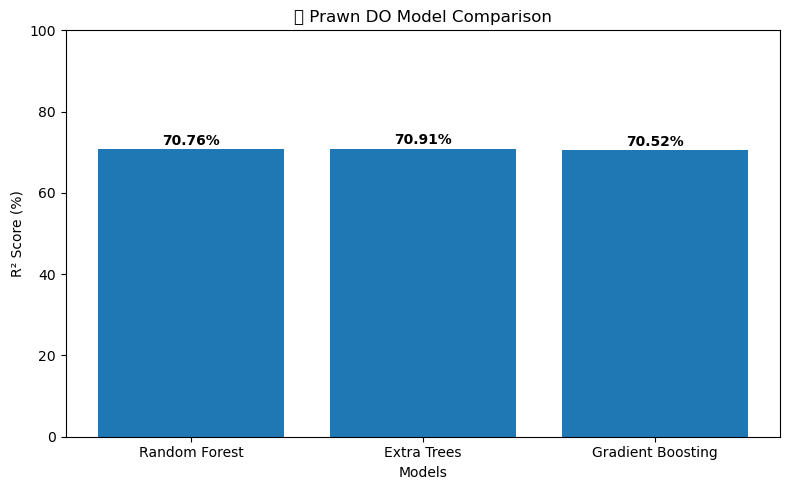

In [18]:
import matplotlib.pyplot as plt

models = [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting"
]

r2_scores = [
    70.76,
    70.91,
    70.52
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    r2_scores
)

plt.xlabel("Models")
plt.ylabel("R² Score (%)")
plt.title("🦐 Prawn DO Model Comparison")
plt.ylim(0, 100)

for bar, value in zip(bars, r2_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## 7. Actual vs Predicted DO

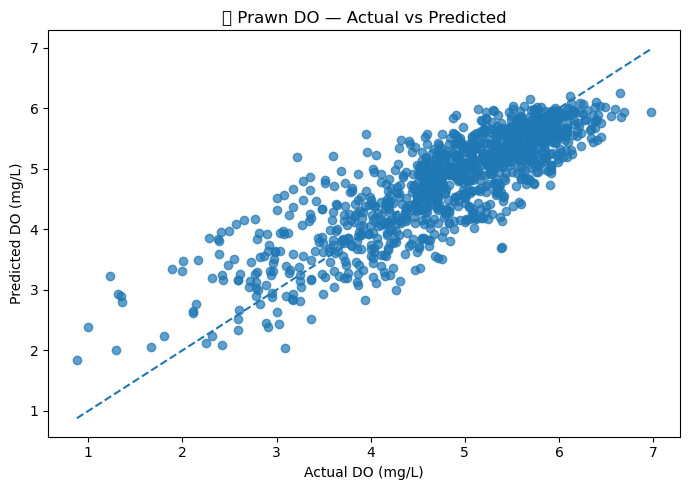

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred, alpha=0.7)

low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual DO (mg/L)")
plt.ylabel("Predicted DO (mg/L)")
plt.title("🦐 Prawn DO — Actual vs Predicted")
plt.tight_layout()
plt.show()


## 8. Feature importance

,Feature,Importance
3,ammonia_mg_L,0.269984
1,pH,0.222628
0,water_temp_C,0.183728
5,turbidity_NTU,0.106337
2,salinity_ppt,0.055511
4,nitrite_mg_L,0.054431
8,aerator_on,0.053812
6,feed_kg,0.016733
7,rainfall_mm,0.010466
13,species_Vannamei (L. vannamei),0.009930


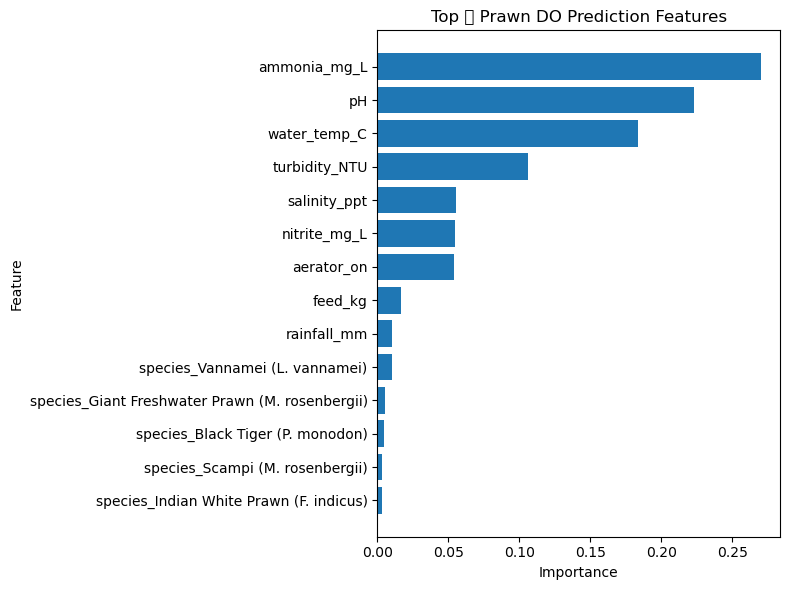

In [10]:
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pipeline.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importance})
    .sort_values("Importance", ascending=False)
)

display(importance_df.head(15))

top = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(top["Feature"], top["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 🦐 Prawn DO Prediction Features")
plt.tight_layout()
plt.show()


## 9. Save the trained model

In [11]:
model_path = MODELS_DIR / "prawn_do_model.pkl"
metadata_path = MODELS_DIR / "prawn_do_metadata.json"

joblib.dump(pipeline, model_path)

metadata = {
    "species": "prawn",
    "dataset": str(DATASET_PATH),
    "target_column": target_col,
    "feature_columns": feature_cols,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "MAE": float(mae),
    "RMSE": float(rmse),
    "R2": float(r2)
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("✅ Model saved to:", model_path)
print("✅ Metadata saved to:", metadata_path)


✅ Model saved to: C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\models\prawn_do_model.pkl
✅ Metadata saved to: C:\Users\NANDINI\Desktop\AquaCare_Complete\prawn\models\prawn_do_metadata.json


## 10. Test one real row from the dataset

The test input below is taken from the actual test set. No fabricated sample is created.

In [12]:
sample = X_test.iloc[[0]].copy()
sample_prediction = float(pipeline.predict(sample)[0])

print("Actual input row:")
display(sample)

print("Predicted DO:", round(sample_prediction, 3), "mg/L")


Actual input row:


,water_temp_C,pH,salinity_ppt,ammonia_mg_L,nitrite_mg_L,turbidity_NTU,feed_kg,rainfall_mm,aerator_on,species
4382,31.82,8.3,25.05,0.06,0.1,37.2,0.0,0.0,0,Indian White Prawn (F. indicus)


Predicted DO: 5.753 mg/L


## 11. DO screening status

These are the current AquaCare project screening bands and should remain configurable for the target species/pond.

In [13]:
DO_THRESHOLDS = {
    "optimal_min": 5.0,
    "moderate_min": 3.0,
    "low_min": 2.0,
}

def classify_do(value):
    if value >= DO_THRESHOLDS["optimal_min"]:
        return "Optimal"
    elif value >= DO_THRESHOLDS["moderate_min"]:
        return "Moderate"
    elif value >= DO_THRESHOLDS["low_min"]:
        return "Low"
    return "Critical"

print("Predicted status:", classify_do(sample_prediction))


Predicted status: Optimal


# ✅ 🦐 Prawn DO training complete

The trained model is saved inside your project:

```text
AQUA CARE/
└── models/
    ├── prawn_do_model.pkl
    └── prawn_do_metadata.json
```

This `.pkl` model can be connected to the Flask AquaCare AI application.
